# Importing Libraries

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import shutil

print("All libraries imported successfully!")

All libraries imported successfully!


# Defining Paths & Settings

In [2]:
RAW_PATH       = Path("../dataset/raw/plantvillage_wheat")
PROCESSED_PATH = Path("../dataset/processed")
CLASSES        = ["healthy", "leaf_rust", "stripe_rust", "powdery_mildew"]
IMG_SIZE       = (224, 224)   # standard CNN input size
MIN_SIZE       = 100          # minimum width or height in pixels

print(f"Raw path       : {RAW_PATH}")
print(f"Processed path : {PROCESSED_PATH}")
print(f"Image size     : {IMG_SIZE}")
print(f"Minimum size   : {MIN_SIZE}px")

Raw path       : ..\dataset\raw\plantvillage_wheat
Processed path : ..\dataset\processed
Image size     : (224, 224)
Minimum size   : 100px


# Creating Output Folder Structure

In [3]:
splits = ["train", "val", "test"]

for split in splits:
    for cls in CLASSES:
        folder = PROCESSED_PATH / split / cls
        folder.mkdir(parents=True, exist_ok=True)

print("Folder structure created successfully!")
print()
for split in splits:
    print(f"  processed/{split}/")
    for cls in CLASSES:
        print(f"    └── {cls}/")

Folder structure created successfully!

  processed/train/
    └── healthy/
    └── leaf_rust/
    └── stripe_rust/
    └── powdery_mildew/
  processed/val/
    └── healthy/
    └── leaf_rust/
    └── stripe_rust/
    └── powdery_mildew/
  processed/test/
    └── healthy/
    └── leaf_rust/
    └── stripe_rust/
    └── powdery_mildew/


# Function: Check If Image Is Too Small

In [4]:
def is_valid_image(img_path, min_size=MIN_SIZE):
    """
    Returns True if image is large enough to use.
    Returns False if image is too small or corrupted.
    """
    try:
        with Image.open(img_path) as img:
            w, h = img.size
            if w < min_size or h < min_size:
                return False
        return True
    except Exception:
        return False

print("Function is_valid_image() defined.")

Function is_valid_image() defined.


# Function: Preprocess One Image

In [5]:
def preprocess_image(img_path, img_size=IMG_SIZE):
    """
    Full DIP pipeline for one image:
    1. Read image
    2. Resize to 224x224
    3. Noise removal (Gaussian blur)
    4. Contrast enhancement (CLAHE)
    5. Return processed image
    """
    # Step 1 — Read image using OpenCV
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # convert BGR to RGB

    # Step 2 — Resize to 224x224
    img = cv2.resize(img, img_size, interpolation=cv2.INTER_AREA)

    # Step 3 — Noise removal using Gaussian blur
    img = cv2.GaussianBlur(img, (3, 3), 0)

    # Step 4 — Contrast enhancement using CLAHE on L channel
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge([l, a, b])
    img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    return img

print("Function preprocess_image() defined.")

Function preprocess_image() defined.


# Visualizing Preprocessing on One Sample Image

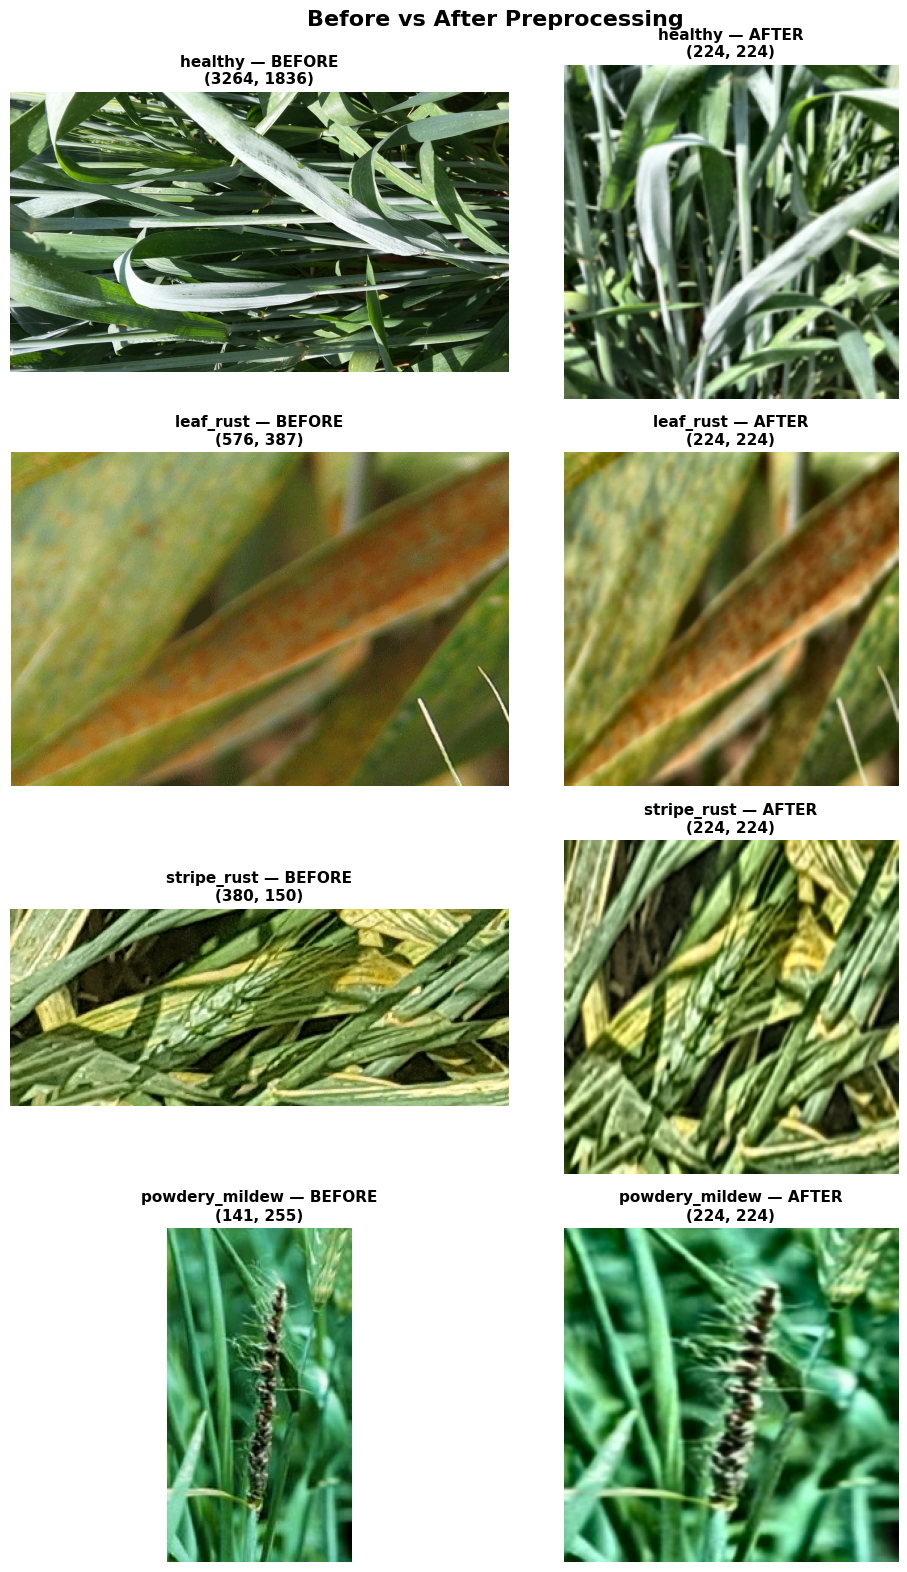

Comparison saved to results/preprocessing_comparison.png


In [6]:
# Pick one sample image from each class and show before/after
fig, axes = plt.subplots(4, 2, figsize=(10, 16))
fig.suptitle("Before vs After Preprocessing", fontsize=16, fontweight="bold")

for row, cls in enumerate(CLASSES):
    folder = RAW_PATH / cls
    images = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))

    # find first valid image
    sample = None
    for img_path in images:
        if is_valid_image(img_path):
            sample = img_path
            break

    # BEFORE
    original = Image.open(sample)
    axes[row][0].imshow(original)
    axes[row][0].axis("off")
    axes[row][0].set_title(f"{cls} — BEFORE\n{original.size}",
                            fontsize=11, fontweight="bold")

    # AFTER
    processed = preprocess_image(sample)
    axes[row][1].imshow(processed)
    axes[row][1].axis("off")
    axes[row][1].set_title(f"{cls} — AFTER\n(224, 224)",
                            fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig("../results/preprocessing_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Comparison saved to results/preprocessing_comparison.png")

# Processing & Splitting Full Dataset

In [7]:
import random
random.seed(42)   # for reproducibility

skipped = 0
saved   = 0

split_ratios = {"train": 0.70, "val": 0.15, "test": 0.15}

print("Processing dataset...\n")

for cls in CLASSES:
    folder = RAW_PATH / cls
    all_images = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))

    # filter out invalid (too small / corrupted) images
    valid_images = [p for p in all_images if is_valid_image(p)]
    skipped += len(all_images) - len(valid_images)

    # shuffle randomly
    random.shuffle(valid_images)

    # calculate split sizes
    total     = len(valid_images)
    n_train   = int(total * 0.70)
    n_val     = int(total * 0.15)

    train_imgs = valid_images[:n_train]
    val_imgs   = valid_images[n_train : n_train + n_val]
    test_imgs  = valid_images[n_train + n_val:]

    split_data = {"train": train_imgs, "val": val_imgs, "test": test_imgs}

    for split, img_list in split_data.items():
        for i, img_path in enumerate(img_list):
            processed = preprocess_image(img_path)
            out_path  = PROCESSED_PATH / split / cls / f"{cls}_{i:04d}.jpg"
            # save as JPEG
            Image.fromarray(processed).save(str(out_path), "JPEG", quality=95)
            saved += 1

    print(f"  {cls:<20} -> {len(train_imgs)} train | {len(val_imgs)} val | {len(test_imgs)} test")

print(f"\n  Total saved   : {saved} images")
print(f"  Total skipped : {skipped} images (too small or corrupted)")
print("\n  Done! Check dataset/processed/ folder.")

Processing dataset...

  healthy              -> 1113 train | 238 val | 240 test
  leaf_rust            -> 591 train | 126 val | 128 test
  stripe_rust          -> 665 train | 142 val | 144 test
  powdery_mildew       -> 609 train | 130 val | 131 test

  Total saved   : 4257 images
  Total skipped : 858 images (too small or corrupted)

  Done! Check dataset/processed/ folder.


# Verification of Processed Dataset

In [8]:
print("=" * 55)
print("       PROCESSED DATASET VERIFICATION")
print("=" * 55)

total_processed = 0

for split in ["train", "val", "test"]:
    print(f"\n  {split.upper()}/")
    split_total = 0
    for cls in CLASSES:
        folder = PROCESSED_PATH / split / cls
        count  = len(list(folder.glob("*.jpg")))
        split_total     += count
        total_processed += count
        print(f"    {cls:<20} : {count} images")
    print(f"    {'SUBTOTAL':<20} : {split_total} images")

print()
print(f"  GRAND TOTAL : {total_processed} images")
print("=" * 55)
print("  Preprocessing complete. Proceed to Notebook 03.")
print("=" * 55)

       PROCESSED DATASET VERIFICATION

  TRAIN/
    healthy              : 1113 images
    leaf_rust            : 591 images
    stripe_rust          : 665 images
    powdery_mildew       : 609 images
    SUBTOTAL             : 2978 images

  VAL/
    healthy              : 238 images
    leaf_rust            : 126 images
    stripe_rust          : 142 images
    powdery_mildew       : 130 images
    SUBTOTAL             : 636 images

  TEST/
    healthy              : 240 images
    leaf_rust            : 128 images
    stripe_rust          : 144 images
    powdery_mildew       : 131 images
    SUBTOTAL             : 643 images

  GRAND TOTAL : 4257 images
  Preprocessing complete. Proceed to Notebook 03.
